# Titanic Data Workflow

By Perry Mertens  
Project 1 :Titanic passenger dataset, distributed through the Seaborn example repository.

This project explores passenger characteristics and survival patterns in the Titanic dataset. 
It uses reusable Python functions to clean data, perform exploratory analysis, and create three visualizations. 
The analysis also considers missing data, assumptions, and limitations.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks", context="talk", palette="pastel")

In [12]:
# Load the dataset and checks
df = pd.read_csv("titanic.csv")

print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

assert df.shape[0] >= 200, "The dataset must contain at least 200 rows."
assert df.shape[1] >= 5, "The dataset must contain at least 5 columns."

df.head()

Rows: 891
Columns: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [13]:
# Inspect data types, missing values, and duplicate rows.
df.info()

missing_values = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
})

display(missing_values.sort_values("missing_count", ascending=False))

print(f"Duplicate rows: {df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,missing_count,missing_percent
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2
sex,0,0.0
pclass,0,0.0
survived,0,0.0
fare,0,0.0
parch,0,0.0
sibsp,0,0.0


Duplicate rows: 107


## Data Cleaning
The original dataset is kept in `df`. To keep the analysis focused, cleaning removes derived or overlapping columns that aren’t needed and labels missing embarkation ports as "Unknown".

Missing ages and deck values are left as they are. Passengers with unknown ages are still included in analyses that don’t require age. Identical rows are also retained, since matching characteristics alone don’t confirm that the records belong to the same passenger.

In [15]:
# Define reusable cleaning functions.
def remove_redundant_columns(data):
    """Return a copy without derived or overlapping columns unused in the analysis."""
    columns_to_remove = [
        "class",
        "who",
        "adult_male",
        "embark_town",
        "alive",
        "alone"
    ]
    return data.drop(columns=columns_to_remove).copy()


def label_missing_embarkation(data):
    """Return a copy with missing embarkation ports labeled as Unknown."""
    cleaned = data.copy()
    cleaned["embarked"] = cleaned["embarked"].fillna("Unknown")
    return cleaned

In [16]:
# Apply cleaning while preserving the original dataset.
cleaned_df = remove_redundant_columns(df)
cleaned_df = label_missing_embarkation(cleaned_df)

assert len(cleaned_df) == len(df), "Cleaning unexpectedly changed the row count."
assert cleaned_df["embarked"].notna().all(), "Embarkation values are still missing."

print(f"Original dataset: {df.shape}")
print(f"Cleaned dataset: {cleaned_df.shape}")
print(f"Missing ages retained: {cleaned_df['age'].isna().sum()}")
print(f"Unknown embarkation ports: {cleaned_df['embarked'].eq('Unknown').sum()}")

cleaned_df.head()

Original dataset: (891, 15)
Cleaned dataset: (891, 9)
Missing ages retained: 177
Unknown embarkation ports: 2


,survived,pclass,sex,age,sibsp,parch,fare,embarked,deck
0,0,3,male,22.0,1,0,7.2500,S,NaN
1,1,1,female,38.0,1,0,71.2833,C,C
2,1,3,female,26.0,0,0,7.9250,S,NaN
3,1,1,female,35.0,1,0,53.1000,S,C
4,0,3,male,35.0,0,0,8.0500,S,NaN


## Exploratory Data Analysis

This analysis examines numeric summaries and survival rates by sex and passenger class. Group sizes indicate how many passengers support each comparison. These comparisons describe associations, not causal relationships.

In [17]:
# Define an exploratory analysis function.
#Return numeric summaries and survival statistics by sex and class.
def explore_passenger_data(data):
    numeric_summary = data[
        ["age", "fare", "sibsp", "parch"]
    ].describe()

    survival_by_sex = data.groupby("sex").agg(
        passengers=("survived", "size"),
        survivors=("survived", "sum"),
        survival_rate=("survived", "mean")
    )

    survival_by_class = data.groupby("pclass").agg(
        passengers=("survived", "size"),
        survivors=("survived", "sum"),
        survival_rate=("survived", "mean")
    )

    for table in (survival_by_sex, survival_by_class):
        table["survival_percent"] = (
            table.pop("survival_rate") * 100
        ).round(1)

    return numeric_summary, survival_by_sex, survival_by_class

In [18]:
# Run the analysis and display the results.
numeric_summary, survival_by_sex, survival_by_class = (
    explore_passenger_data(cleaned_df)
)

print("Numeric summary")
display(numeric_summary)

print("Survival by sex")
display(survival_by_sex)

print("Survival by passenger class")
display(survival_by_class)

Numeric summary


,age,fare,sibsp,parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


Survival by sex


,passengers,survivors,survival_percent
sex,,,
female,314,233,74.2
male,577,109,18.9


Survival by passenger class


,passengers,survivors,survival_percent
pclass,,,
1,216,136,63.0
2,184,87,47.3
3,491,119,24.2


## Visualizations

Figure 1 shows the distribution of recorded passenger ages. Figures 2 and 3 compare observed survival rates by sex and passenger class.
These are descriptive comparisons within this dataset.

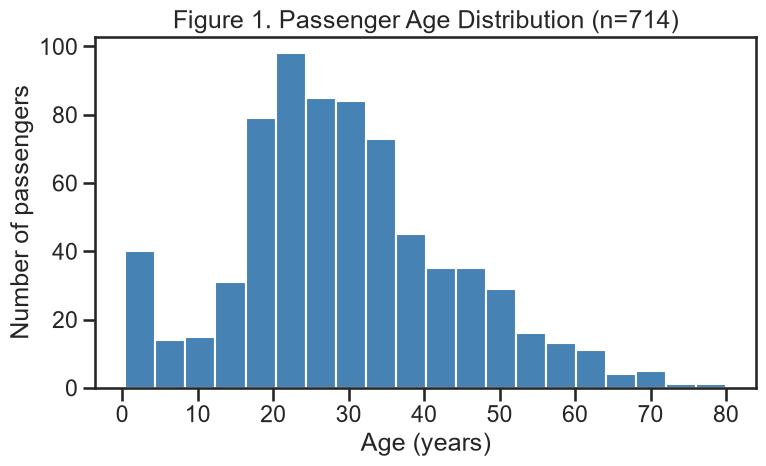

In [19]:
# Plot recorded ages and exclude missing ages only from this figure.
known_ages = cleaned_df["age"].dropna()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(known_ages, bins=20, color="steelblue", edgecolor="white")

ax.set_title(f"Figure 1. Passenger Age Distribution (n={len(known_ages)})")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")

fig.tight_layout()
fig.savefig("figure_1_age_distribution.png", dpi=150)
plt.show()

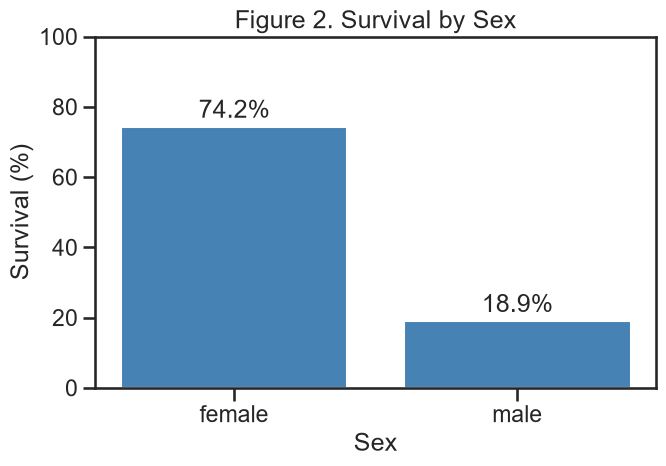

In [20]:
# Plot survival percentages by recorded sex.
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    survival_by_sex.index,
    survival_by_sex["survival_percent"],
    color="steelblue"
)

ax.set_title("Figure 2. Survival by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Survival (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, fmt="%.1f%%", padding=3)

fig.tight_layout()
fig.savefig("figure_2_survival_by_sex.png", dpi=150)
plt.show()

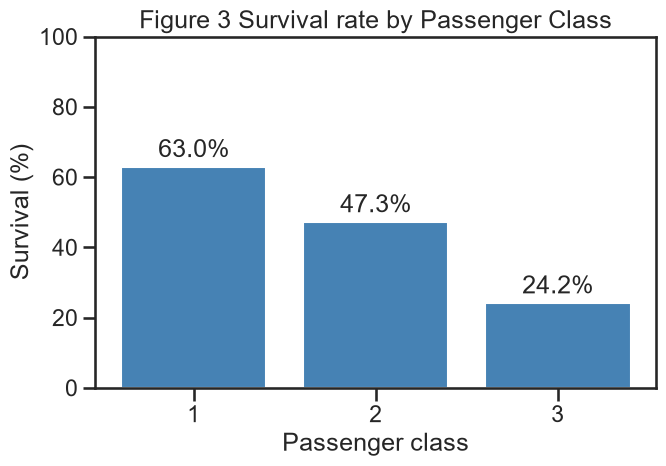

In [24]:
# Plot survival percentages by passenger class.
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    survival_by_class.index.astype(str),
    survival_by_class["survival_percent"],
    color="steelblue"
)

ax.set_title("Figure 3 Survival rate by Passenger Class")
ax.set_xlabel("Passenger class")
ax.set_ylabel("Survival (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, fmt="%.1f%%", padding=3)

fig.tight_layout()
fig.savefig("figure_3_survival__rate_by_class.png", dpi=150)
plt.show()

## Summary and Interpretation

The dataset contains 891 passengers. Ages are recorded for 714 passengers, with a mean of 29.7 years and a median of 28 years. Figure 1 shows the age distribution for these recorded ages; the 177 passengers with missing ages are excluded only from this figure.

Figure 2 shows that 74.2% of female passengers survived, compared with 18.9% of male passengers. Figure 3 shows survival percentages of 63.0% for first-class passengers, 47.3% for second-class passengers, and 24.2% for third-class passengers. These comparisons show associations within the dataset and do not establish why the differences occurred.

Ticket fares show a large difference between the mean of 32.20 and the median of 14.45, with a maximum of 512.33. This indicates a right-skewed distribution. Zero fares are also present, but this analysis does not establish whether they represent valid fares or data-recording issues.

All passenger rows were retained during cleaning. Missing embarkation ports were labeled as "Unknown", while missing ages and deck values were preserved. Derived or overlapping columns were removed from the working dataset, and the original data remained available in `df`.

The missing ages limit the interpretation of Figure 1 because the age distribution of passengers with unrecorded ages is unknown. Deck information is missing for 77.2% of passengers and was not used in the visualizations. The grouped survival comparisons do not adjust for other passenger characteristics, and the findings should not be generalized beyond this dataset without further investigation.